# Módulo 5 — Extensión opcional: *added value* con estaciones de Perú

**No se evalúa ni es obligatoria.** Requiere la extensión del Módulo 3,
Día 5 ([`05_extension_opcional_peru.ipynb`](../../modulo_03_descarga_datos_entrada/notebooks/05_extension_opcional_peru.ipynb)),
que descarga `era5_land_peru_20241213.nc` (ERA5-Land, ~9 km) para el área
de las 7 estaciones de Perú. Aquí se suma `era5_peru_20241213.nc` (ERA5
estándar, ~31 km, mismo día y área), descargado con
`data/era_muestra/descarga_era5_peru.py`.

**Por qué no comparamos con el WRF:** el dominio del WRF de muestra no
cubre el Perú, así que no hay una salida del WRF para estas estaciones.
Hacemos la misma pregunta del *added value* (¿la mayor resolución aporta
algo?) con dos reanálisis de ECMWF: **ERA5-Land (9 km)** y **ERA5 estándar
(31 km)**, los dos interpolados a la ubicación de cada estación y
comparados contra la misma observación.

In [1]:
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from metricas import calcular_mae, calcular_rmse, calcular_bias, calcular_r, calcular_kge

coords_peru = json.load(open("../../../data/ogimet/coords_peru.json"))
era5_land = xr.open_dataset("../../../data/era_muestra/era5_land_peru_20241213.nc")
era5 = xr.open_dataset("../../../data/era_muestra/era5_peru_20241213.nc")

print("ERA5-Land (9 km): ", dict(era5_land.sizes))
print("ERA5 (31 km):     ", dict(era5.sizes))

tiempos_modelo = pd.to_datetime(era5_land["valid_time"].values)

ERA5-Land (9 km):  {'valid_time': 24, 'latitude': 191, 'longitude': 141}
ERA5 (31 km):      {'valid_time': 24, 'latitude': 77, 'longitude': 57}


## Interpolar los dos productos a las 7 estaciones y comparar con la observación

Las estaciones peruanas de OGIMET reportan cada 3 horas, no cada hora como
las del dominio del WRF. Usamos `.reindex(tiempos_modelo)` (como en el
resto del curso) y descartamos las horas sin reporte en vez de inventar un
valor.

**Algo que encontramos al correr este notebook:** ERA5-Land solo tiene
datos sobre tierra; los puntos de grilla sobre el mar están vacíos. En
ciudades muy costeras (Lima, Tumbes) alguno de los 4 nodos de la
interpolación bilineal puede caer en el mar, y `.interp()` devuelve `NaN`
aunque el punto más cercano tenga dato. Es la elección entre nearest e
interp del Módulo 2, en un caso concreto.

In [2]:
filas = []
detalle = {}
notas_cobertura = {}
for nombre, c in coords_peru.items():
    obs_horaria = pd.read_csv(f"../../../data/obs/{nombre}_2024_12_13_horario.csv",
                               parse_dates=["tiempo"]).set_index("tiempo")
    obs_temp = obs_horaria.reindex(tiempos_modelo)["temp_C"]

    # ERA5-Land es SOLO TIERRA: los 4 nodos que rodean a una ciudad muy
    # costera pueden incluir mar (enmascarado, NaN) y .interp() bilineal
    # devuelve NaN si CUALQUIERA de los 4 nodos vecinos es NaN. Se intenta
    # primero interpolar; si sale NaN, se cae a sel(nearest) (mismo criterio
    # nearest-vs-interp del Modulo 2) antes de descartar la estacion.
    t2m_land_interp = era5_land["t2m"].interp(latitude=c["lat"], longitude=c["lon"], method="linear")
    if bool(t2m_land_interp.isnull().any()):
        t2m_land = era5_land["t2m"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest").values - 273.15
        notas_cobertura[nombre] = "nearest (interp bilineal cayo en mar enmascarado)"
    else:
        t2m_land = t2m_land_interp.values - 273.15
        notas_cobertura[nombre] = "interp"

    t2m_era5 = era5["t2m"].interp(latitude=c["lat"], longitude=c["lon"], method="linear").values - 273.15

    valido = obs_temp.notna().values
    o = obs_temp.values[valido]
    detalle[nombre] = (tiempos_modelo[valido], o, t2m_land[valido], t2m_era5[valido])

    for fuente_nombre, serie_full in [("ERA5-Land (9 km)", t2m_land), ("ERA5 (31 km)", t2m_era5)]:
        s = serie_full[valido]
        if np.all(np.isnan(s)):
            filas.append({"estacion": nombre, "fuente": fuente_nombre, "n": len(o),
                          "bias": np.nan, "MAE": np.nan, "RMSE": np.nan, "r": np.nan, "KGE": np.nan})
            continue
        kge_i, comp_i = calcular_kge(s, o)
        filas.append({
            "estacion": nombre, "fuente": fuente_nombre, "n": len(o),
            "bias": calcular_bias(s, o), "MAE": calcular_mae(s, o),
            "RMSE": calcular_rmse(s, o), "r": comp_i["r"], "KGE": kge_i,
        })

print("Cobertura de ERA5-Land por estacion:", notas_cobertura)
tabla_peru = pd.DataFrame(filas).set_index(["estacion", "fuente"]).round(3)
tabla_peru


Cobertura de ERA5-Land por estacion: {'Lima': 'nearest (interp bilineal cayo en mar enmascarado)', 'Cuzco': 'interp', 'Arequipa': 'interp', 'Tacna': 'interp', 'Piura': 'interp', 'Chiclayo': 'interp', 'Tumbes': 'nearest (interp bilineal cayo en mar enmascarado)'}


n   bias    MAE   RMSE      r    KGE
estacion fuente                                                
Lima     ERA5-Land (9 km)  8 -0.313  1.010  1.144  0.808  0.608
         ERA5 (31 km)      8 -1.335  1.335  1.527  0.846  0.735
Cuzco    ERA5-Land (9 km)  8 -3.840  3.840  4.183  0.780  0.538
         ERA5 (31 km)      8 -3.066  3.066  3.386  0.861  0.702
Arequipa ERA5-Land (9 km)  6 -1.092  1.092  1.110  0.997  0.920
         ERA5 (31 km)      6 -1.798  1.798  1.913  0.999  0.698
Tacna    ERA5-Land (9 km)  8 -0.282  0.798  0.956  0.989  0.705
         ERA5 (31 km)      8 -0.251  1.034  1.171  0.990  0.611
Piura    ERA5-Land (9 km)  8 -0.139  0.998  1.156  0.974  0.877
         ERA5 (31 km)      8 -0.589  0.675  0.856  0.989  0.973
Chiclayo ERA5-Land (9 km)  7  0.863  0.899  1.181  0.994  0.708
         ERA5 (31 km)      7  0.533  0.533  0.601  0.996  0.947
Tumbes   ERA5-Land (9 km)  5    NaN    NaN    NaN    NaN    NaN
         ERA5 (31 km)      5  1.542  1.542  1.952  0.895  0.244

In [3]:
tabla_peru.to_csv("validacion_peru_era5land_vs_era5.csv")

resumen = tabla_peru.groupby("fuente")[["RMSE", "KGE"]].mean()
print("Promedio simple sobre las 7 estaciones:")
print(resumen)
print()
gana_land_rmse = resumen.loc["ERA5-Land (9 km)", "RMSE"] < resumen.loc["ERA5 (31 km)", "RMSE"]
gana_land_kge = resumen.loc["ERA5-Land (9 km)", "KGE"] > resumen.loc["ERA5 (31 km)", "KGE"]
print(f"¿ERA5-Land (mayor resolución) mejora RMSE en promedio? -> {gana_land_rmse}")
print(f"¿ERA5-Land (mayor resolución) mejora KGE en promedio?  -> {gana_land_kge}")

Promedio simple sobre las 7 estaciones:
                      RMSE       KGE
fuente                              
ERA5 (31 km)      1.629429  0.701429
ERA5-Land (9 km)  1.621667  0.726000

¿ERA5-Land (mayor resolución) mejora RMSE en promedio? -> True
¿ERA5-Land (mayor resolución) mejora KGE en promedio?  -> True


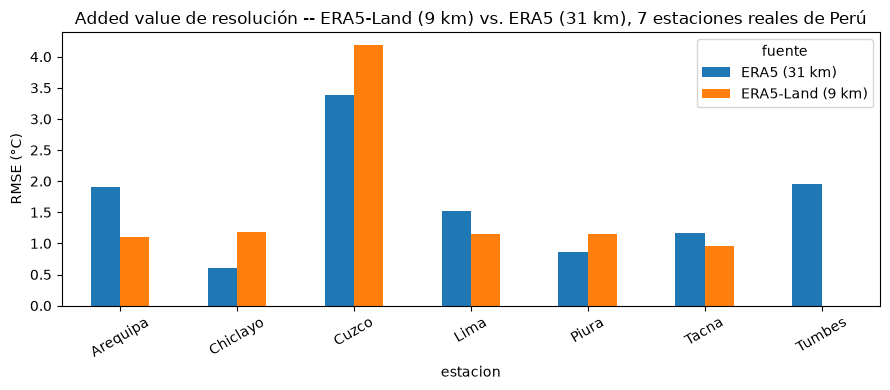

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
tabla_peru["RMSE"].unstack("fuente").plot(kind="bar", ax=ax)
ax.set_ylabel("RMSE (°C)")
ax.set_title("Added value de resolución -- ERA5-Land (9 km) vs. ERA5 (31 km), 7 estaciones reales de Perú")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

## Lectura del resultado (a completar por el grupo)

Igual que con WRF y ERA5-Land, no esperamos que gane siempre el producto de
mayor resolución. El terreno del Perú (costa árida, sierra alta, selva) es
muy variado, y pasar de 31 km a 9 km puede importar o no según el relieve
cerca de cada estación (comparen, por ejemplo, Cuzco o Arequipa, en la
sierra, con Piura o Tumbes, en la costa plana). Preguntas para la puesta en
común:

- ¿En qué estaciones ERA5-Land (mayor resolución) mejora claramente sobre
  ERA5 estándar? ¿Son las de terreno más complejo?
- ¿Coincide con lo que vimos en el dominio del WRF, donde el producto de
  mayor resolución (WRF) tampoco le ganó siempre a ERA5-Land?

## Cierre

Entregable de esta extensión (si se completa): este notebook +
`validacion_peru_era5land_vs_era5.csv`. Vuelve al flujo principal del curso
en [`README.md`](../README.md) del Módulo 5.